# 1.3 Evaluation metrics

Confusion matrix, ROC/AUC, and a lift chart for the classification target
(`churned`); MAE, RMSE and MAPE for the regression target (`monthly_spend`).
Same table, same train/test split, just read off with different metrics.

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


In [2]:
from sklearn.model_selection import train_test_split
from plotting import plot_confusion, plot_roc, plot_lift

features = ["age","tenure_months","income_k","monthly_usage","support_calls","discount_pct","satisfaction"]
X = df[features]

## Classification metrics: confusion matrix, ROC/AUC, lift

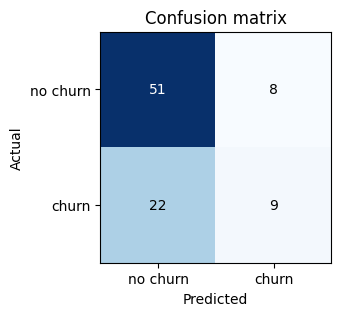

Precision: 0.529
Recall   : 0.29
F1       : 0.375


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score

y = df["churned"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
clf = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
y_pred = clf.predict(Xte)
y_score = clf.predict_proba(Xte)[:, 1]

cm = plot_confusion(yte, y_pred)
plt.show()
print("Precision:", round(precision_score(yte, y_pred), 3))
print("Recall   :", round(recall_score(yte, y_pred), 3))
print("F1       :", round(f1_score(yte, y_pred), 3))

The confusion matrix's four cells (true/false positive, true/false
negative) are the building blocks behind precision, recall and F1 above --
exactly the "building blocks" the slides start from before naming any
metric.

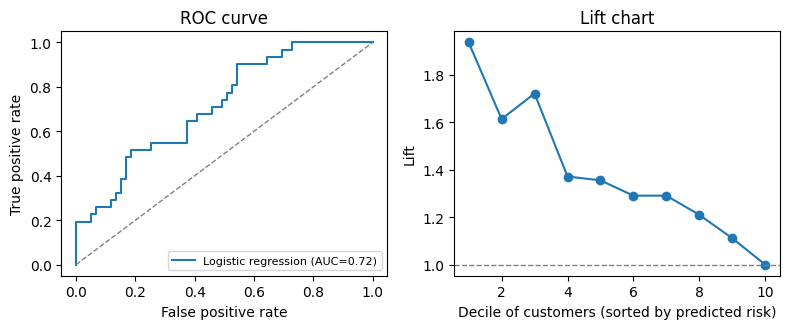

AUC: 0.715


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
auc_val = plot_roc(yte, y_score, ax=axes[0], label="Logistic regression")
plot_lift(yte, y_score, ax=axes[1])
plt.tight_layout(); plt.show()
print("AUC:", round(auc_val, 3))

The ROC curve plots true-positive rate against false-positive rate as the
decision threshold sweeps from 0 to 1 -- AUC summarises it in one number
(0.5 = coin flip, 1.0 = perfect separation). The lift chart instead asks a
business question: if you contact the top decile of customers ranked by
predicted churn risk, how many times more churners do you catch than
contacting a random decile? A lift well above 1 in the first bars, tapering
toward 1, is exactly what makes a churn model useful for a retention
campaign.

## Regression metrics: MAE, RMSE, MAPE

MAE  = 4.56  (average absolute euro error)
RMSE = 5.67  (penalises big misses more than MAE)
MAPE = 11.9%  (error as a % of the true spend -- scale-free)


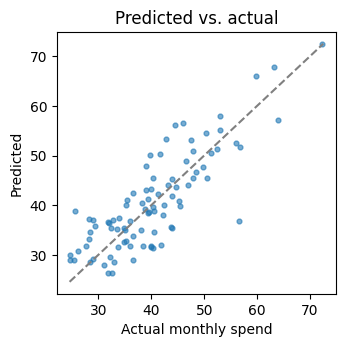

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

yr = df["monthly_spend"]
Xtr, Xte, ytr, yte = train_test_split(X, yr, test_size=0.3, random_state=0)
reg = LinearRegression().fit(Xtr, ytr)
pred = reg.predict(Xte)

mae = mean_absolute_error(yte, pred)
rmse = mean_squared_error(yte, pred) ** 0.5
mape = mean_absolute_percentage_error(yte, pred)
print(f"MAE  = {mae:.2f}  (average absolute euro error)")
print(f"RMSE = {rmse:.2f}  (penalises big misses more than MAE)")
print(f"MAPE = {mape*100:.1f}%  (error as a % of the true spend -- scale-free)")

fig, ax = plt.subplots(figsize=(3.6, 3.4))
ax.scatter(yte, pred, s=12, alpha=0.6)
lims = [min(yte.min(), pred.min()), max(yte.max(), pred.max())]
ax.plot(lims, lims, "--", color="grey")
ax.set_xlabel("Actual monthly spend"); ax.set_ylabel("Predicted"); ax.set_title("Predicted vs. actual")
plt.show()

**Takeaway**: classification metrics answer "how well-separated are my two
classes, and at what operating point?"; regression metrics answer "how far
off, on average, is my prediction, in the target's own units (MAE/RMSE) or
scale-free (MAPE)?". Same train/test discipline from the resampling
notebook applies to both.